# 01 - Feature Noise Thresholds & Asymptotic Null Distributions

## Overview
When automated feature engineering platforms explore thousands of candidate features, some will appear to have high predictive power purely by chance. 

In this notebook, we show:
1. **The Mathematical Foundations:** How Wilks' Theorem links **Relative Information Gain (RIG)** to the Chi-squared ($\chi^2$) distribution.
2. **Analytical vs. Permutation Tests:** Comparing instantaneous closed-form estimators against Monte-Carlo permutations.
3. **The Drivers of Noise:** Verifying why null RIG depends on **sample size ($N$)** and **minority class proportion**, but *not* feature support.
4. **Setting Search-Space-Aware Thresholds:** Using Bonferroni and Extreme Value Theory (EVT) to set rigorous statistical noise gates given $M$ evaluated features.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Ensure local sampling_toolbox is importable
sys.path.insert(0, os.path.abspath('..'))

from signalgate import (
    rig, 
    entropy, 
    FeatureNoiseThreshold, 
    estimate_noise_threshold, 
    PermutationObject
)

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


## 1. Information Theory & Wilks' Theorem

For a boolean feature $X \in \{0, 1\}$ and discrete target $Y$, Relative Information Gain is defined as:
$$\text{RIG}(X, Y) = \frac{I(X; Y)}{H(Y)} = \frac{H(Y) - H(Y \mid X)}{H(Y)}$$

Under the null hypothesis $H_0$ that $X$ and $Y$ are independent:
$$2 N \ln(2) \cdot I(X; Y) \xrightarrow{d} \chi^2_{df}$$
where $df = (|X| - 1)(|Y| - 1) = 1$ for boolean features and binary targets.

Dividing by the target prior entropy $H(Y)$:
$$\text{RIG}_{\text{null}} \sim \frac{\chi^2_1}{2 N \ln(2) \cdot H(Y)}$$

Let's test this theoretical expectation against empirical Monte-Carlo permutations!


In [2]:
# Setup synthetic data matching a typical binary classification dataset
nrows = 2000
minority_fraction = 0.25  # 25% minority class
n_permutations = 5000

# Analytical Estimator
estimator = FeatureNoiseThreshold(nrows=nrows, target_distribution=minority_fraction)
print(f"Sample size N = {nrows}, Target Entropy H(Y) = {estimator.target_entropy:.4f} bits")
print(f"Analytical Expected Mean Null RIG   = {estimator.expected_null_mean:.6f}")
print(f"Analytical Expected Median Null RIG = {estimator.expected_null_median:.6f}")
print(f"Analytical 99.9% (1-in-1000) Cutoff = {estimator.quantile_threshold(0.999):.6f}")


Sample size N = 2000, Target Entropy H(Y) = 0.8113 bits
Analytical Expected Mean Null RIG   = 0.000445
Analytical Expected Median Null RIG = 0.000202
Analytical 99.9% (1-in-1000) Cutoff = 0.004814


In [3]:
# Run high-performance Monte-Carlo permutations
perm = PermutationObject()
perm.set_data_parameters(nrows=nrows, class_weights=[minority_fraction])
perm.feature_fractions = [0.10]
perm.create_synthetic_data(seed=42)

print(f"Running {n_permutations} vectorized permutations...")
null_df = perm.calculate_null_rigs(permutations=n_permutations, seed=42)


Running 5000 vectorized permutations...


Max null RIG 		= 0.007840
Median null RIG 	= 0.000214
1 in 5000 null RIG 	= 0.005938
Gain threshold 		= 0.000500


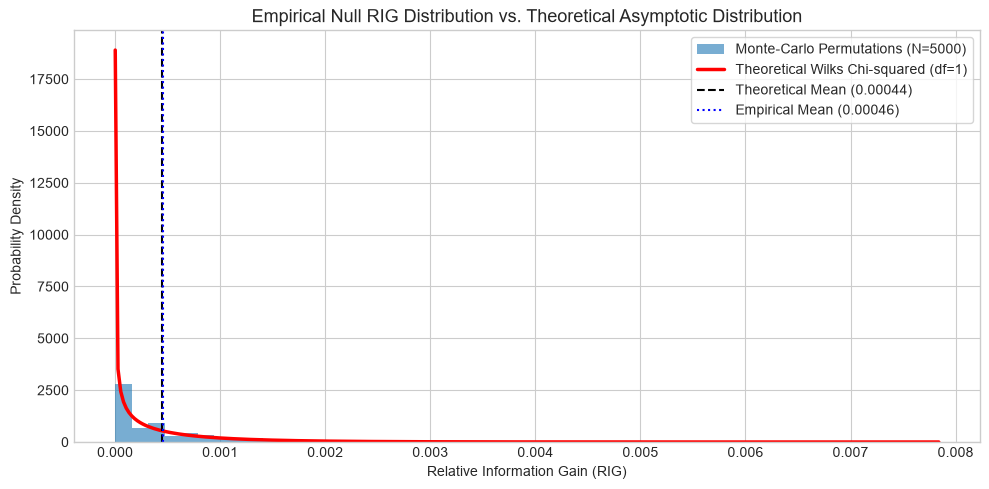

In [4]:
# Compare empirical distribution to theoretical Chi-squared density
fig, ax = plt.subplots(figsize=(10, 5))

# Plot empirical null RIGs
counts, bins, _ = ax.hist(perm.null_rig_values, bins=50, density=True, alpha=0.6, 
                          color='#1f77b4', label=f'Monte-Carlo Permutations (N={n_permutations})')

# Overlay theoretical Chi2 density scaled to RIG
x_vals = np.linspace(1e-6, perm.null_rig_values.max(), 300)
# pdf_RIG(r) = pdf_Chi2(r * C) * C
c = estimator.scaling_factor
theoretical_pdf = stats.chi2.pdf(x_vals * c, df=1) * c

ax.plot(x_vals, theoretical_pdf, 'r-', lw=2.5, label='Theoretical Wilks Chi-squared (df=1)')
ax.axvline(estimator.expected_null_mean, color='black', linestyle='--', label=f'Theoretical Mean ({estimator.expected_null_mean:.5f})')
ax.axvline(perm.null_rig_values.mean(), color='blue', linestyle=':', label=f'Empirical Mean ({perm.null_rig_values.mean():.5f})')

ax.set_title('Empirical Null RIG Distribution vs. Theoretical Asymptotic Distribution', fontsize=13)
ax.set_xlabel('Relative Information Gain (RIG)')
ax.set_ylabel('Probability Density')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


## 2. Investigating What Drives Null RIG

From the analytical formula:
$$\mathbb{E}[\text{RIG}_{\text{null}}] = \frac{1}{2 N \ln(2) \cdot H(Y)}$$

Notice two critical theoretical predictions:
1. **Feature support $P(X=1)$ does NOT affect the mean null RIG**, because the degrees of freedom $(|X|-1)(|Y|-1) = 1$ is invariant to marginal feature proportions.
2. **Minority class fraction strongly affects null RIG**, because as the minority class gets rarer, prior entropy $H(Y)$ decreases, pushing the noise floor higher.
3. **Null RIG scales inversely with sample size ($O(1/N)$)**.

Let's verify these systematically:


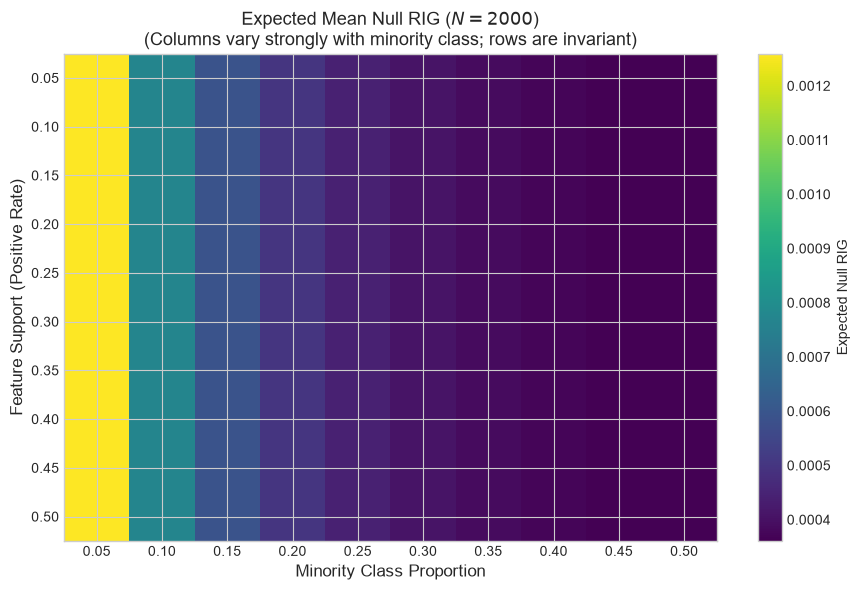

In [5]:
# Evaluate mean null RIG across a grid of feature support vs target support
feature_supports = np.linspace(0.05, 0.50, 10)
target_supports = np.linspace(0.05, 0.50, 10)

grid_results = np.zeros((len(feature_supports), len(target_supports)))

for i, f_sup in enumerate(feature_supports):
    for j, t_sup in enumerate(target_supports):
        # We can evaluate this instantly using the analytical estimator
        est = FeatureNoiseThreshold(nrows=2000, target_distribution=t_sup)
        grid_results[i, j] = est.expected_null_mean

df_grid = pd.DataFrame(
    grid_results, 
    index=[f"{f:.2f}" for f in feature_supports],
    columns=[f"{t:.2f}" for t in target_supports]
)

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(df_grid, cmap='viridis', aspect='auto')
ax.set_xticks(np.arange(len(target_supports)))
ax.set_yticks(np.arange(len(feature_supports)))
ax.set_xticklabels([f"{t:.2f}" for t in target_supports])
ax.set_yticklabels([f"{f:.2f}" for f in feature_supports])
ax.set_xlabel('Minority Class Proportion', fontsize=12)
ax.set_ylabel('Feature Support (Positive Rate)', fontsize=12)
ax.set_title('Expected Mean Null RIG ($N=2000$)\n(Columns vary strongly with minority class; rows are invariant)', fontsize=13)
cbar = plt.colorbar(im)
cbar.set_label('Expected Null RIG')
plt.tight_layout()
plt.show()


## 3. Controlling for Multiple Hypothesis Testing ($M$ Evaluated Features)

When an AutoML platform evaluates $M$ candidate features (e.g. $M = 10,000$ or $1,000,000$ across transformations, ngram tokens, numerical cuts, and context datasets), the probability of finding at least one high-RIG spurious feature approaches 100%.

We provide two analytical thresholds:
* **Bonferroni / Šidák Significance Threshold:** Controls Family-Wise Error Rate (FWER) at level $\alpha$ (e.g. 0.05) across $M$ tests:
  $$\tau_{\text{significance}} = \frac{\text{ppf}_{\chi^2_1}(1 - \alpha / M)}{2 N \ln(2) H(Y)}$$
* **Extreme Value Theory (EVT) Expected Max:** The expected maximum noise score evaluated across $M$ independent features:
  $$\mathbb{E}[\max_{1 \le i \le M} \chi^2_1] \approx 2 \ln M - \ln \ln M - \ln \pi + 2\gamma$$


In [6]:
# Case Study: Titanic Dataset (N=720, Minority Class = 36.9%)
titanic_estimator = FeatureNoiseThreshold(nrows=720, target_distribution=0.369)

search_spaces = [10, 50, 100, 500, 1000, 5000, 10000, 50000, 100000, 1000000]
summary_df = titanic_estimator.evaluate_search_space(feature_counts=search_spaces, alpha=0.05)
summary_df


,Features Evaluated (M),Expected Mean Null RIG,1-in-M Null RIG,EVT Expected Max Noise RIG,Significance Threshold (alpha=0.05)
0,10,0.001055,0.002854,0.003988,0.008311
1,50,0.001055,0.005708,0.006824,0.011420
2,100,0.001055,0.006998,0.008114,0.012779
3,500,0.001055,0.010072,0.011193,0.015965
4,1000,0.001055,0.011420,0.012543,0.017348
5,5000,0.001055,0.014588,0.015717,0.020579
6,10000,0.001055,0.015965,0.017097,0.021977
7,50000,0.001055,0.019184,0.020322,0.025237
8,100000,0.001055,0.020579,0.021719,0.026646
9,1000000,0.001055,0.025237,0.026384,0.031343


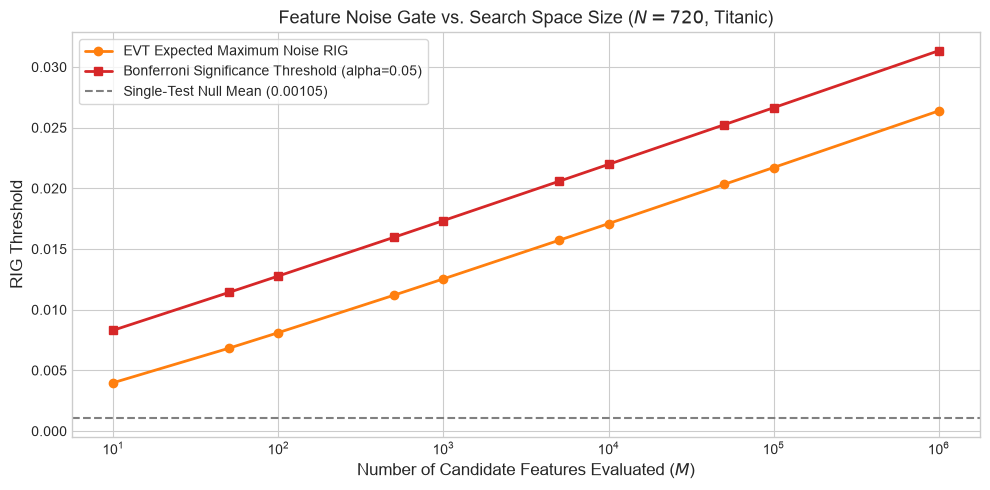

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(summary_df["Features Evaluated (M)"], summary_df["EVT Expected Max Noise RIG"], 
        'o-', color='#ff7f0e', lw=2, label='EVT Expected Maximum Noise RIG')
ax.plot(summary_df["Features Evaluated (M)"], summary_df["Significance Threshold (alpha=0.05)"], 
        's-', color='#d62728', lw=2, label='Bonferroni Significance Threshold (alpha=0.05)')
ax.axhline(titanic_estimator.expected_null_mean, color='gray', linestyle='--', label=f'Single-Test Null Mean ({titanic_estimator.expected_null_mean:.5f})')

ax.set_xscale('log')
ax.set_xlabel('Number of Candidate Features Evaluated ($M$)', fontsize=12)
ax.set_ylabel('RIG Threshold', fontsize=12)
ax.set_title('Feature Noise Gate vs. Search Space Size ($N=720$, Titanic)', fontsize=13)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


## 4. Key Takeaways & Quick Usage

1. **Instant Calculation:** You don't need to spend minutes running permutations. `estimate_noise_threshold(nrows, minority_frac, n_features_evaluated)` computes the exact threshold in microseconds.
2. **Dynamic Gating:** The threshold required for a feature to be considered "better than noise" increases logarithmically with search budget $M$, and inversely with dataset size $N$.
3. **Imbalanced Targets:** When the minority class is small ($p < 0.10$), target entropy is low, causing spurious features to register substantially higher RIG values by pure chance.

```python
from signalgate import estimate_noise_threshold

# Instant lookup: 5,000 rows, 15% minority class, 20,000 features explored in AutoML
tau = estimate_noise_threshold(nrows=5000, minority_frac=0.15, n_features_evaluated=20000, alpha=0.05)
print(f"Noise gate: RIG must exceed {tau:.5f}")
```
